In [1]:
import socket

# Stop before importing scientific packages if the notebook is opened on a gateway.
if "hgtw" in socket.gethostname().lower() or "gtwy" in socket.gethostname().lower():
    raise RuntimeError("Run this notebook on a Slurm compute node")


In [36]:
from pathlib import Path
import os
import sys
import pandas as pd
import numpy as np
import muon as mu
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns

os.environ["PATH"] = os.path.dirname(sys.executable) + os.pathsep + os.environ["PATH"]

PROJECT_DIR = Path("/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER")
TETHER_DIR = PROJECT_DIR / "TETHER"
DATA_DIR = PROJECT_DIR / "data"
GENOME = "hg38"

PROCESSED_DATA_DIR = DATA_DIR / "processed" / GENOME

In [ ]:
processed_datasets = pd.DataFrame(columns=["dataset_name", "sample_name", "data_path"])
for dataset_name_dir in PROCESSED_DATA_DIR.iterdir():
    if dataset_name_dir.is_dir():
        for sample_dir in dataset_name_dir.iterdir():
            if sample_dir.is_dir():
                if "multiome_processed.h5mu" in [f.name for f in sample_dir.iterdir() if f.is_file()]:
                    processed_datasets = pd.concat([processed_datasets, pd.DataFrame({"dataset_name": [dataset_name_dir.name], "sample_name": [sample_dir.name], "data_path": [str(sample_dir / "multiome_processed.h5mu")]})], ignore_index=True)
                else:
                    print(f"Skipping {sample_dir} as it does not contain 'multiome_processed.h5mu'.")
            else:
                print(f"Skipping {sample_dir} as it is not a directory.")
    else:
        print(f"Skipping {dataset_name_dir} as it is not a directory.")

processed_datasets

,dataset_name,sample_name,data_path
0,ENCODE_adrenal,adrenal_adult_ENCDO221IPH,/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_C...
1,ENCODE_adrenal,adrenal_adult_ENCDO856ZOJ,/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_C...
2,GSE207335_epidermis,S2,/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_C...
3,GSE207335_epidermis,S1,/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_C...
4,GSE194122_bone_marrow,s1d1,/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_C...
5,GSE194122_bone_marrow,s1d2,/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_C...
6,ENCODE_lung,lung_child_ENCDO575EGL,/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_C...
7,ENCODE_lung,lung_adult_ENCDO528BHB,/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_C...
8,ENCODE_vena_cava,vena_cava_adult_ENCDO221IPH,/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_C...
9,ENCODE_bile_duct,bile_duct_adult_ENCDO575WHY,/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_C...


In [49]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    mdata_sample = mu.read_h5mu(processed_datasets.loc[0, "data_path"])
mdata_sample

MuData object with n_obs × n_vars = 6291 × 156428
  obs:	'dataset', 'library'
  var:	'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
  uns:	'source'
  2 modalities
    rna:	6291 x 26837
      obs:	'barcode_rna', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'outlier', 'mt_outlier', 'leiden_res0_25', 'leiden_res0_5', 'leiden_res1', 'leiden_res1_25', 'Endothelial_score', 'Pericyte/smooth muscle_score', 'Fibroblast_score', 'T cell_score', 'NK cell_score', 'B cell_score', 'Plasma cell_score', 'Monocyte_score', 'Macrophage_score', 'Dendritic cell_score', 'Mast cell_score', 'Adrenal cortex (fasciculata)_score', 'Adrenal cortex (glomerulosa)_score', 'Chromaffin cell_score', 'Adipocyte_score', 'Cycling cells_score', 'Ventricular cardiomyocyte_score', 'Atrial cardiomyocyte_score', 'Mesothelial_score', 'Neural cell_score', 'celltype'
      var:	'gene_id', 'gene_ids', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
      uns:	'celltype_colors', 'de_genes', 'dendrogram_leiden_res0_5', 'dendrogram_leiden_res1', 'hvg', 'leiden_res0_25', 'leiden_res0_25_colors', 'leiden_res0_5', 'leiden_res0_5_colors', 'leiden_res1', 'leiden_res1_25', 'leiden_res1_25_colors', 'leiden_res1_colors', 'log1p', 'neighbors', 'pca', 'umap'
      obsm:	'X_pca', 'X_umap'
      varm:	'PCs'
      layers:	'counts'
      obsp:	'connectivities', 'distances'
    atac:	6291 x 129591
      obs:	'n_genes_by_counts', 'total_counts', 'tss_score', 'outlier', 'NS', 'nucleosome_signal', 'n_counts', 'leiden'
      var:	'chrom', 'start', 'end', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'nearest_gene', 'TSS_dist', 'TSS_dist_score'
      uns:	'files', 'leiden', 'leiden_colors', 'log1p', 'lsi', 'neighbors', 'peak_gene_distance_params', 'peak_gene_links', 'umap'
      obsm:	'X_lsi', 'X_umap'
      varm:	'LSI'
      layers:	'counts'
      obsp:	'connectivities', 'distances'

In [68]:
def plot_feature_ridge_plot(processed_datasets, column_path, title):
    import h5py
    distributions = []

    for sample in processed_datasets.itertuples(index=False):
        with h5py.File(sample.data_path, "r") as h5:
            rna_distribution = h5[column_path][:]

        distributions.append({
            "name": sample.sample_name,
            "data": rna_distribution,
        })

    samples = []
    for sample in distributions:
        values = np.asarray(sample["data"], dtype=float)
        values = values[np.isfinite(values)]
        if values.size:
            samples.append((sample["name"], values))

    if not samples:
        raise ValueError("No samples contain valid n_genes_by_counts values.")

    fig, axes = plt.subplots(
        nrows=len(samples),
        ncols=1,
        figsize=(10, max(2.5, 0.25 * len(samples) + 0.8)),
        sharex=True,
        squeeze=False,
    )
    axes = axes[:, 0]

    colors = sns.color_palette("viridis", n_colors=len(samples))

    for i, (ax, (name, values), color) in enumerate(zip(axes, samples, colors)):
        ax.set_zorder(i + 1)
        ax.set_facecolor("none")

        if np.ptp(values) == 0:
            # A constant sample has no spread for a KDE.
            ax.axvline(values[0], color=color, linewidth=2)
        else:
            sns.kdeplot(
                x=values,
                ax=ax,
                fill=True,
                color=color,
                alpha=0.7,
                linewidth=1.2,
                cut=0,
                bw_adjust=0.8,
            )

        ax.axhline(0, color=color, linewidth=0.8)
        ax.text(
            -0.02, 0.12, f"{name} (n={len(values):,})",
            transform=ax.transAxes, ha="right", va="bottom",
        )
        ax.set_ylabel("")
        ax.set_yticks([])
        sns.despine(ax=ax, left=True, bottom=i < len(samples) - 1)

    axes[-1].set_xlabel("Detected genes per cell")
    fig.subplots_adjust(left=0.28, hspace=-0.35)

    fig.suptitle(title, fontsize=16, y=0.95)

    plt.show()

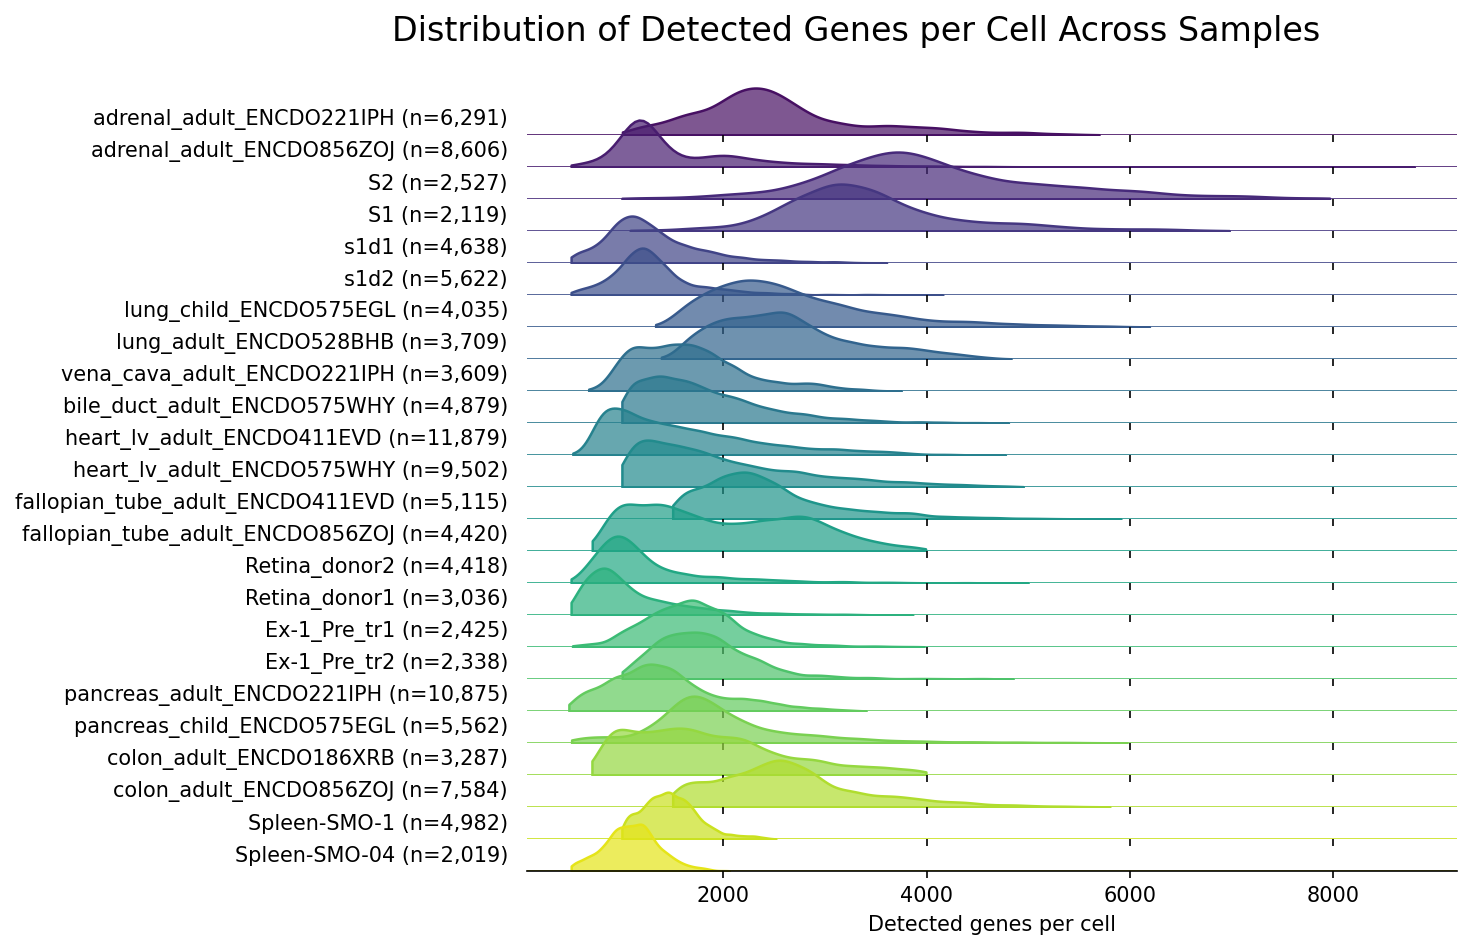

In [69]:
column_path = "/mod/rna/obs/n_genes_by_counts"

plot_feature_ridge_plot(processed_datasets, column_path, title="Distribution of Detected Genes per Cell Across Samples")